# Load the data

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from sklearn.model_selection import train_test_split

***
# Process the data into training, validation, and test sets

In [8]:
# Function to load the data
def load_data():
    (X_train, y_train), (X_test, y_test) = mnist.load_data()
    return X_train, y_train, X_test, y_test

# Function to Flatten the images
def flatten_images(X_train, X_test):
    X_train = X_train.reshape(X_train.shape[0], -1) # Flatten the images
    X_test = X_test.reshape(X_test.shape[0], -1) # Flatten the images
    return X_train, X_test # Return the flattened images

# Function to One-hot encode the labels
def one_hot_encode(y, num_classes):  # One-hot encode the labels
    return np.eye(num_classes)[y] # Return the one-hot encoded labels

# Function to Normalize the data between 0 and 1 by dividing by 255
def normalize_data(X_train, X_val, X_test): # Normalize the data
    X_train = X_train / 255.0 # Normalize the data
    X_val = X_val / 255.0 # Normalize the data
    X_test = X_test / 255.0 # Normalize the data 
    return X_train, X_val, X_test # Return the normalized data

# Function to Split the data into training and validation sets
def split_data(X_train, y_train, validation_size=0.1667):
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=validation_size, random_state=42)
    return X_train, y_train, X_val, y_val

In [9]:
# Load the data
X_train, y_train, X_test, y_test = load_data()

# Flatten the images
X_train, X_test = flatten_images(X_train, X_test)

# One-hot encode the labels
y_train = one_hot_encode(y_train, 10)
y_test = one_hot_encode(y_test, 10)

# Split the training data into training and validation sets using sklearn
X_train, y_train, X_val, y_val = split_data(X_train, y_train)

# Normalize the data
X_train, X_val, X_test = normalize_data(X_train, X_val, X_test)

# Check the shapes to ensure everything is correct
print(f"Training set shape: {X_train.shape}, {y_train.shape}")
print(f"Validation set shape: {X_val.shape}, {y_val.shape}")
print(f"Test set shape: {X_test.shape}, {y_test.shape}")

Training set shape: (49998, 784), (49998, 10)
Validation set shape: (10002, 784), (10002, 10)
Test set shape: (10000, 784), (10000, 10)


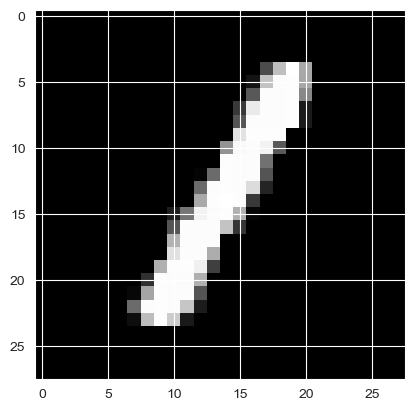

In [10]:
# Display a sample image
plt.imshow(X_train[0].reshape(28, 28), cmap='gray')

***
# Define the Neural Network

In [27]:
# Function to initialize the parameters
def initialize_parameters(input_size, hidden_size, output_size):
    W1 = np.random.randn(hidden_size, input_size) * 0.01 # Initialize the first set of weights
    b1 = np.zeros((hidden_size, 1)) # Initialize the first set of biases
    W2 = np.random.randn(output_size, hidden_size) * 0.01 # Initialize the second set of weights
    b2 = np.zeros((output_size, 1)) # Initialize the second set of biases
    return W1, b1, W2, b2

# Define the activation functions
def relu(x): 
    return np.maximum(0, x) # ReLU activation function

# Define the derivative of the ReLU activation function
def relu_derivative(x):
    return np.where(x <= 0, 0, 1) # Derivative of the ReLU activation function

# Define the softmax activation function for the output layer
def softmax(x):
    exps = np.exp(x - np.max(x, axis=0, keepdims=True)) # Subtract the maximum value to prevent overflow
    return exps / np.sum(exps, axis=0, keepdims=True) # Softmax activation function

# Define the forward propagation step to compute the output of the neural network
def forward_propagation(X, W1, b1, W2, b2, keep_prob=0.8): # Forward propagation
    Z1 = np.dot(W1, X) + b1  # Compute the weighted sum of the inputs
    A1 = relu(Z1) # Apply the ReLU activation function
    D1 = np.random.rand(A1.shape[0], A1.shape[1]) < keep_prob # Dropout mask
    A1 = np.multiply(A1, D1) # Apply dropout
    A1 /= keep_prob # Scale the activations
    Z2 = np.dot(W2, A1) + b2 # Compute the weighted sum of the hidden layer
    A2 = softmax(Z2) # Apply the softmax activation function
    return Z1, A1, Z2, A2, D1 # Return the intermediate outputs

# Define the cross-entropy loss function 
def cross_entropy_loss(y_true, y_pred, W1, W2, lambda_reg): 
    m = y_true.shape[1] # Number of samples
    log_likelihood = -np.log(y_pred[y_true.argmax(axis=0), range(m)] + 1e-8) # Compute the log-likelihood
    loss = np.sum(log_likelihood) / m # Compute the loss
    reg_loss = (lambda_reg / (2 * m)) * (np.sum(np.square(W1)) + np.sum(np.square(W2))) # Regularization loss
    return loss + reg_loss

# Define the backward propagation step to compute the gradients of the loss function with respect to the parameters
def backward_propagation(X, Y, Z1, A1, Z2, A2, W1, W2, D1, keep_prob=0.8):
    m = X.shape[1] # Number of samples
    dZ2 = A2 - Y # Compute the gradient of the loss with respect to Z2
    dW2 = (1 / m) * np.dot(dZ2, A1.T) # Compute the gradient of the loss with respect to W2
    db2 = (1 / m) * np.sum(dZ2, axis=1, keepdims=True) # Compute the gradient of the loss with respect to b2
    dA1 = np.dot(W2.T, dZ2) # Compute the gradient of the loss with respect to A1
    dA1 = np.multiply(dA1, D1) # Apply dropout
    dA1 /= keep_prob # Scale the activations
    dZ1 = dA1 * relu_derivative(Z1) # Compute the gradient of the loss with respect to Z1
    dW1 = (1 / m) * np.dot(dZ1, X.T) # Compute the gradient of the loss with respect to W1
    db1 = (1 / m) * np.sum(dZ1, axis=1, keepdims=True) # Compute the gradient of the loss with respect to b1
    return dW1, db1, dW2, db2

# Define the function to update the parameters 
def update_parameters(W1, b1, W2, b2, dW1, db1, dW2, db2, learning_rate):
    W1 -= learning_rate * dW1 # Update the first set of weights
    b1 -= learning_rate * db1 # Update the first set of biases
    W2 -= learning_rate * dW2 # Update the second set of weights
    b2 -= learning_rate * db2 # Update the second set of biases
    return W1, b1, W2, b2

# Define the function to train the neural network
def train_neural_network(X_train, y_train, X_val, y_val, hidden_size, learning_rate, epochs, batch_size, lambda_reg, keep_prob, patience=10): # Train the neural network
    input_size = X_train.shape[1] # Input size
    output_size = y_train.shape[1] # Output size
    W1, b1, W2, b2 = initialize_parameters(input_size, hidden_size, output_size) # Initialize the parameters
    best_val_loss = float('inf') # Initialize the best validation loss
    patience_counter = 0 # Initialize the patience counter
    
    # Train the neural network
    for epoch in range(epochs):
        permutation = np.random.permutation(X_train.shape[0]) # Shuffle the training data
        X_train_shuffled = X_train[permutation] # Shuffle the training data
        y_train_shuffled = y_train[permutation] # Shuffle the training data
        
        # Loop over the training data in batches
        for i in range(0, X_train.shape[0], batch_size): # Loop over the training data
            X_batch = X_train_shuffled[i:i + batch_size].T # Get a batch of inputs
            Y_batch = y_train_shuffled[i:i + batch_size].T # Get a batch of outputs
            
            # Perform forward and backward propagation
            Z1, A1, Z2, A2, D1 = forward_propagation(X_batch, W1, b1, W2, b2, keep_prob) # Forward propagation
            dW1, db1, dW2, db2 = backward_propagation(X_batch, Y_batch, Z1, A1, Z2, A2, W1, W2, D1, keep_prob)
            W1, b1, W2, b2 = update_parameters(W1, b1, W2, b2, dW1, db1, dW2, db2, learning_rate)
        
        # Compute the validation loss
        Z1, A1, Z2, A2, _ = forward_propagation(X_val.T, W1, b1, W2, b2)
        val_loss = cross_entropy_loss(y_val.T, A2, W1, W2, lambda_reg)
        
        # Print the validation loss every 10 epochs
        if epoch % 10 == 0:
            print(f"Epoch {epoch}, Val Loss: {val_loss}")
        
        # Early stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
        else:
            patience_counter += 1
        
        # Break out of the loop if the validation loss does not improve for 'patience' epochs
        if patience_counter >= patience:
            print(f"Early stopping at epoch {epoch}")
            break
    
    return W1, b1, W2, b2

# Define the function to evaluate the model on the test set
def evaluate_model(X_test, y_test, W1, b1, W2, b2):
    _, _, _, A2, _ = forward_propagation(X_test.T, W1, b1, W2, b2, keep_prob=1.0)  # No dropout during evaluation
    predictions = np.argmax(A2, axis=0)
    labels = np.argmax(y_test.T, axis=0)
    accuracy = np.mean(predictions == labels)
    return accuracy

In [28]:
# Train the neural network
W1, b1, W2, b2 = train_neural_network(
    X_train, y_train, X_val, y_val,
    hidden_size=124, learning_rate=0.04, epochs=150, batch_size=64,
    lambda_reg=0.01, keep_prob=0.8, patience=10
)

# Evaluate the model on the validation set
val_accuracy = evaluate_model(X_val, y_val, W1, b1, W2, b2)
print(f"Validation Accuracy: {val_accuracy}")

Epoch 0, Val Loss: 0.45376501451994933
Epoch 10, Val Loss: 0.16873297600079304
Epoch 20, Val Loss: 0.12302440898831608
Epoch 30, Val Loss: 0.11091543844057396
Epoch 40, Val Loss: 0.10074674291167574
Epoch 50, Val Loss: 0.09605357419681197
Epoch 60, Val Loss: 0.0891077996773795
Epoch 70, Val Loss: 0.09238991223034228
Early stopping at epoch 75
Validation Accuracy: 0.9799040191961608


***
# Post-training Evaluation

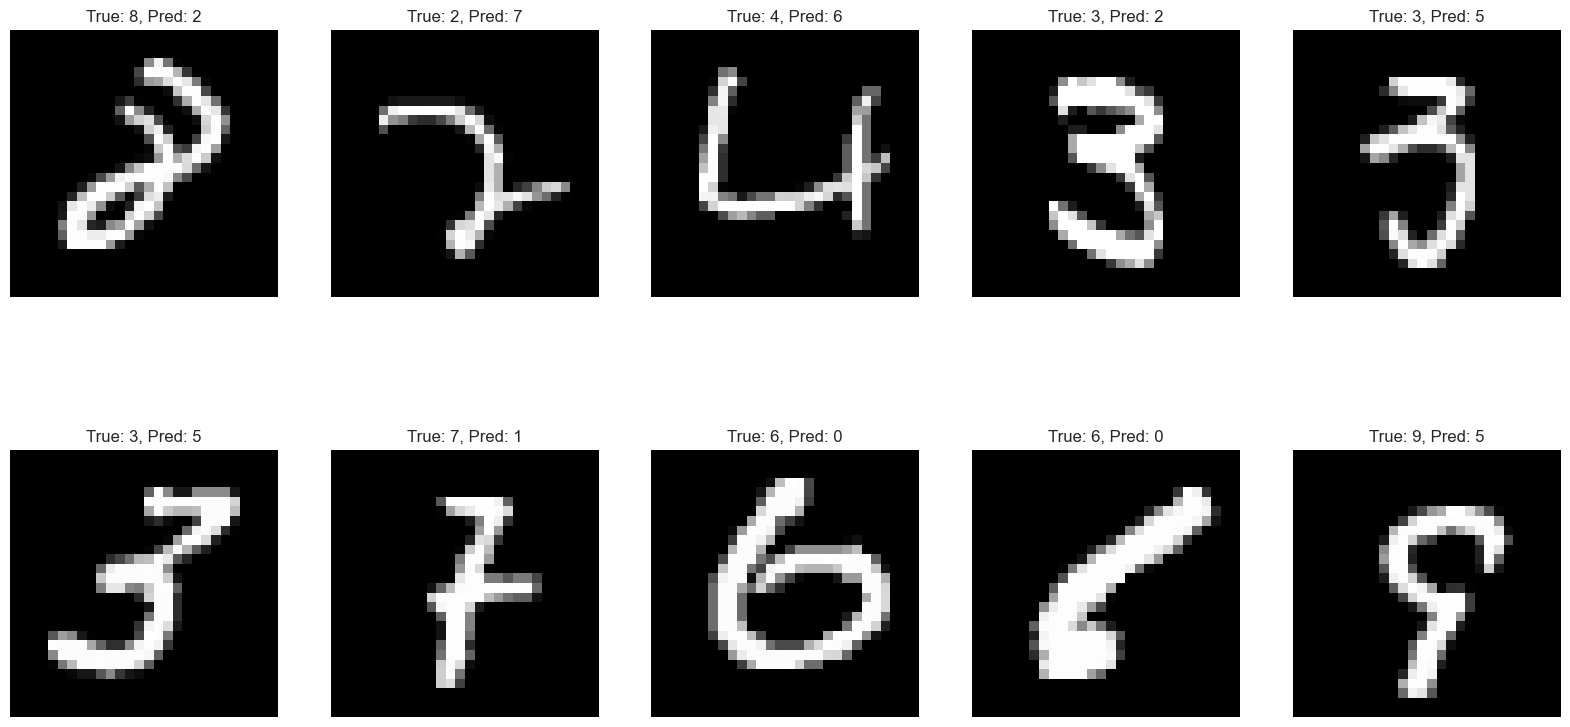

In [29]:
# Show the misclassified images
Z1, A1, Z2, A2, _ = forward_propagation(X_val.T, W1, b1, W2, b2)
predictions = np.argmax(A2, axis=0)
labels = np.argmax(y_val.T, axis=0)
misclassified_indices = np.where(predictions != labels)[0]

# Display the misclassified images
plt.figure(figsize=(20, 10))
for i, index in enumerate(misclassified_indices[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_val[index].reshape(28, 28), cmap='gray')
    plt.title(f"True: {labels[index]}, Pred: {predictions[index]}")
    plt.axis('off')

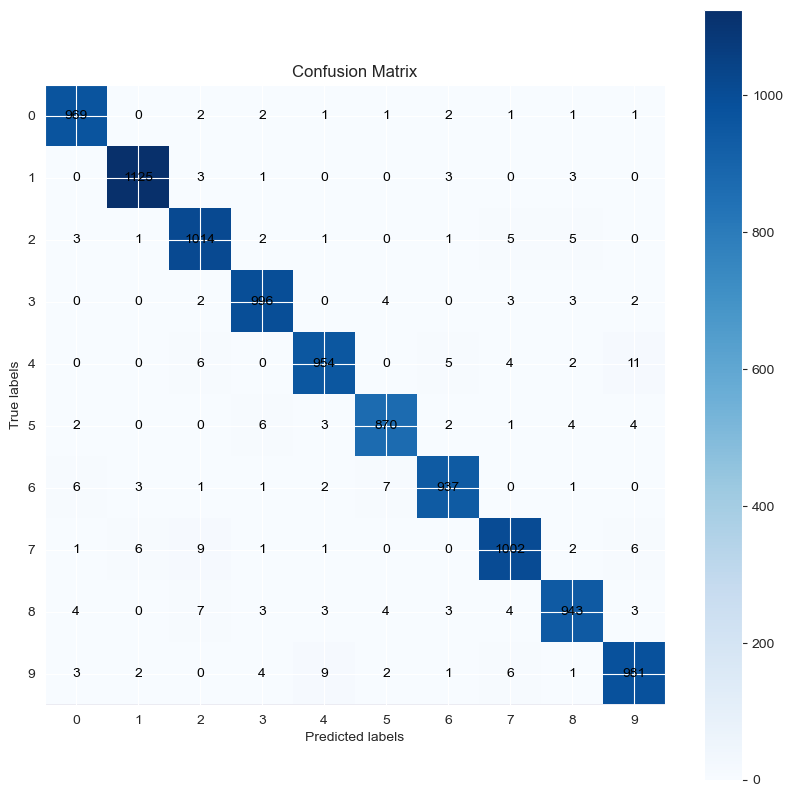

In [35]:
# Create a confusion matrix
from sklearn.metrics import confusion_matrix

# Compute the predictions on the test set
Z1, A1, Z2, A2, _ = forward_propagation(X_test.T, W1, b1, W2, b2, keep_prob=1.0)

# Compute the confusion matrix
predictions = np.argmax(A2, axis=0)
conf_matrix = confusion_matrix(np.argmax(y_test.T, axis=0), predictions)

# Display the confusion matrix
plt.figure(figsize=(10, 10))
plt.imshow(conf_matrix, cmap='Blues')
plt.colorbar()
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.xticks(np.arange(10))
plt.yticks(np.arange(10))
plt.title('Confusion Matrix')

# Annotate the confusion matrix with numbers
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        plt.text(j, i, conf_matrix[i, j], ha='center', va='center', color='black')

plt.show()


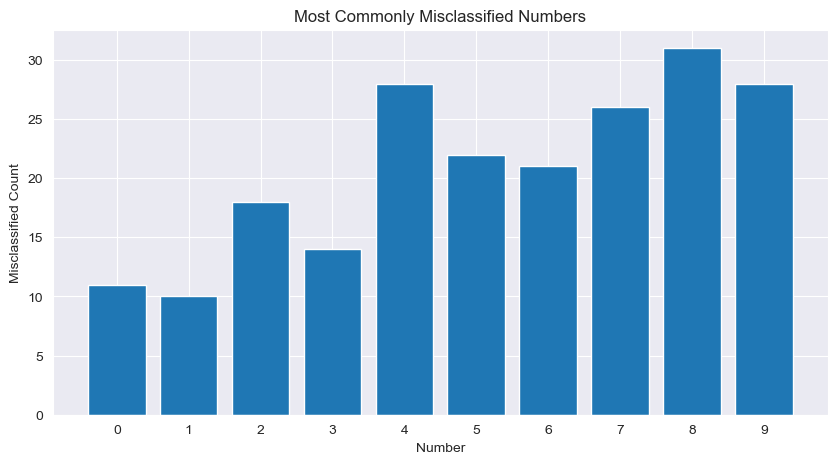

In [36]:
# Which numbers are most commonly misclassified?
misclassified_counts = np.sum(conf_matrix, axis=1) - np.diag(conf_matrix)

# Display the most commonly misclassified numbers
plt.figure(figsize=(10, 5))
plt.bar(np.arange(10), misclassified_counts)
plt.xlabel('Number')
plt.ylabel('Misclassified Count')
plt.title('Most Commonly Misclassified Numbers')
plt.xticks(np.arange(10))
plt.show()

In [39]:
# Find the numbers that each digit is most commonly misclassified as

def most_commonly_misclassified_as(conf_matrix, digit):
    conf_matrix[digit, digit] = -1  # Temporarily set the diagonal element to a value that can't be the max
    misclassified_as = np.argmax(conf_matrix[digit, :])
    conf_matrix[digit, digit] = np.sum(conf_matrix[digit, :])  # Restore the diagonal element
    return misclassified_as

# List of digits
digits = list(range(10))

# Find the misclassifications
for digit in digits:
    misclassified_as = most_commonly_misclassified_as(conf_matrix, digit)
    print(f"Number {digit} is most commonly misclassified as: {misclassified_as}")


Number 0 is most commonly misclassified as: 2
Number 1 is most commonly misclassified as: 2
Number 2 is most commonly misclassified as: 7
Number 3 is most commonly misclassified as: 5
Number 4 is most commonly misclassified as: 9
Number 5 is most commonly misclassified as: 3
Number 6 is most commonly misclassified as: 5
Number 7 is most commonly misclassified as: 2
Number 8 is most commonly misclassified as: 2
Number 9 is most commonly misclassified as: 4
